# 04 · Mold risk assessment, validation and early-warning model

## Risk definition (transparent rule, `src/risk.py`)

For every reading and location:

| Level | Condition | Rationale |
|---|---|---|
| **high** | dew point margin ≤ 0 °C (condensation) **or** humidity above the LIM curve now **and** for ≥ 50 % of the valid time of the last 7 days | liquid water on the surface, or moisture that persists long enough for germination |
| **medium** | humidity above the LIM curve **or** dew point margin 0–3 °C | conditions allow germination if they persist; near-condensation |
| **low** | otherwise | |
| *unknown* | inputs missing | never counted as low |

Humidity is the **surface** relative humidity where a surface sensor exists, otherwise
room air (notebook 03). LIM class I is the default. All shares are divided by **valid
hours**.

In [1]:
import sys, pathlib, itertools
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.tree import plot_tree

from src import config as C, load_data as L, results, plotting as P, risk as R, model as M
from src.features import episodes

P.setup()
pd.set_option("display.width", 170, "display.max_columns", 40)
np.random.seed(C.RANDOM_SEED)
df = L.load_processed()
risk = R.risk_table(df)
risk.to_parquet(C.RISK_FILE)
names = {s: P.name(s) for s in C.INDOOR}
print(risk.shape)
risk.apply(lambda c: c.value_counts(dropna=False)).rename(index={0.0: "low", 1.0: "medium", 2.0: "high"}).rename(columns=names)

(48971, 8)


,Organ,North wall,South wall,East wall,Art objects NW,Art objects S,Attic,Basement
low,39987,5009,20875,21272,13233,37258,38251,15080
medium,2335,715,2368,2073,3973,5348,3996,4220
high,6586,2417,3148,986,13522,6364,5211,20469
NaN,63,40830,22580,24640,18243,1,1513,9202


## 1 · Results per location (full period, each location over its own valid data)

,valid_h,coverage,share_high,share_medium,share_low,n_high_episodes,longest_high_h,n_elevated_episodes,longest_elevated_h,score,rank
location,,,,,,,,,,,
Basement,13256,81%,51.5%,10.6%,37.9%,63,1075,86,1134,0.568,1
Art objects NW,10243,63%,44.0%,12.9%,43.1%,85,1076,144,1076,0.505,2
North wall,2714,17%,29.7%,8.8%,61.5%,28,229,58,303,0.341,3
Art objects S,16323,100%,13.0%,10.9%,76.1%,90,187,316,187,0.185,4
South wall,8797,54%,11.9%,9.0%,79.1%,56,215,137,215,0.164,5
Organ,16303,100%,13.5%,4.8%,81.8%,28,1096,146,1131,0.159,6
Attic,15819,97%,11.0%,8.4%,80.6%,78,173,233,173,0.152,7
East wall,8110,50%,4.1%,8.5%,87.4%,15,111,113,170,0.083,8


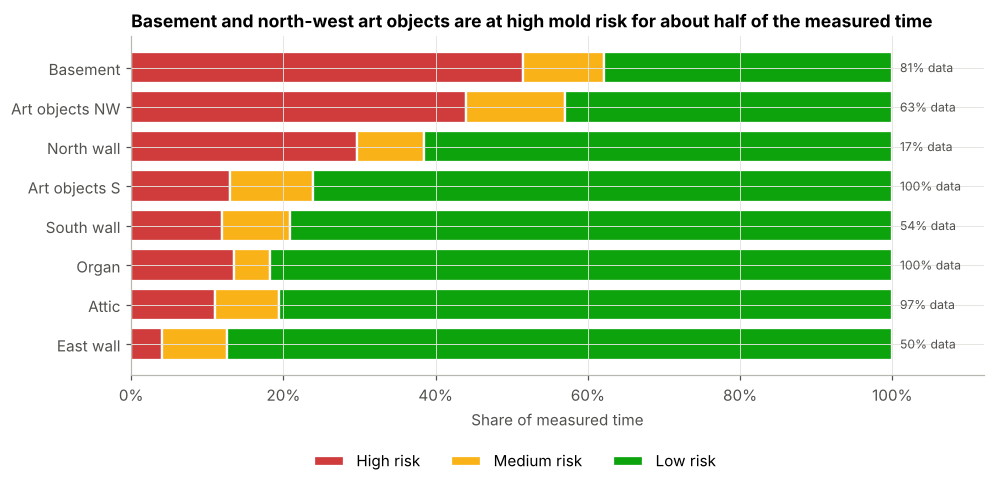

In [2]:
full = R.summarize(risk)
show = full.rename(index=names)
display(show.style.format({"valid_h": "{:.0f}", "coverage": "{:.0%}", "share_high": "{:.1%}", "share_medium": "{:.1%}",
                           "share_low": "{:.1%}", "longest_high_h": "{:.0f}", "longest_elevated_h": "{:.0f}",
                           "score": "{:.3f}", "rank": "{:.0f}"}))
results.save_table(show.round(4), "risk_summary_full")

fig, ax = plt.subplots(figsize=(10, 4))
order = full.index[::-1]
left = np.zeros(len(order))
for lvl, key, lab in [(2, "share_high", "High"), (1, "share_medium", "Medium"), (0, "share_low", "Low")]:
    v = full.loc[order, key].values
    ax.barh([names[s] for s in order], v, left=left, color=P.STATUS[P.LEVEL_NAMES[lvl]], label=f"{lab} risk",
            edgecolor="white", linewidth=1.5)
    left += v
for i, s in enumerate(order):
    ax.text(1.01, i, f"{full.loc[s, 'coverage']:.0%} data", va="center", fontsize=8, color=P.INK2)
ax.set_xlim(0, 1.12); ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("Share of measured time"); ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.45, -0.32))
ax.set_title("Basement and north-west art objects are at high mold risk for about half of the measured time")
P.save(fig, "04_risk_shares_full.png"); plt.show()

### Monthly profile

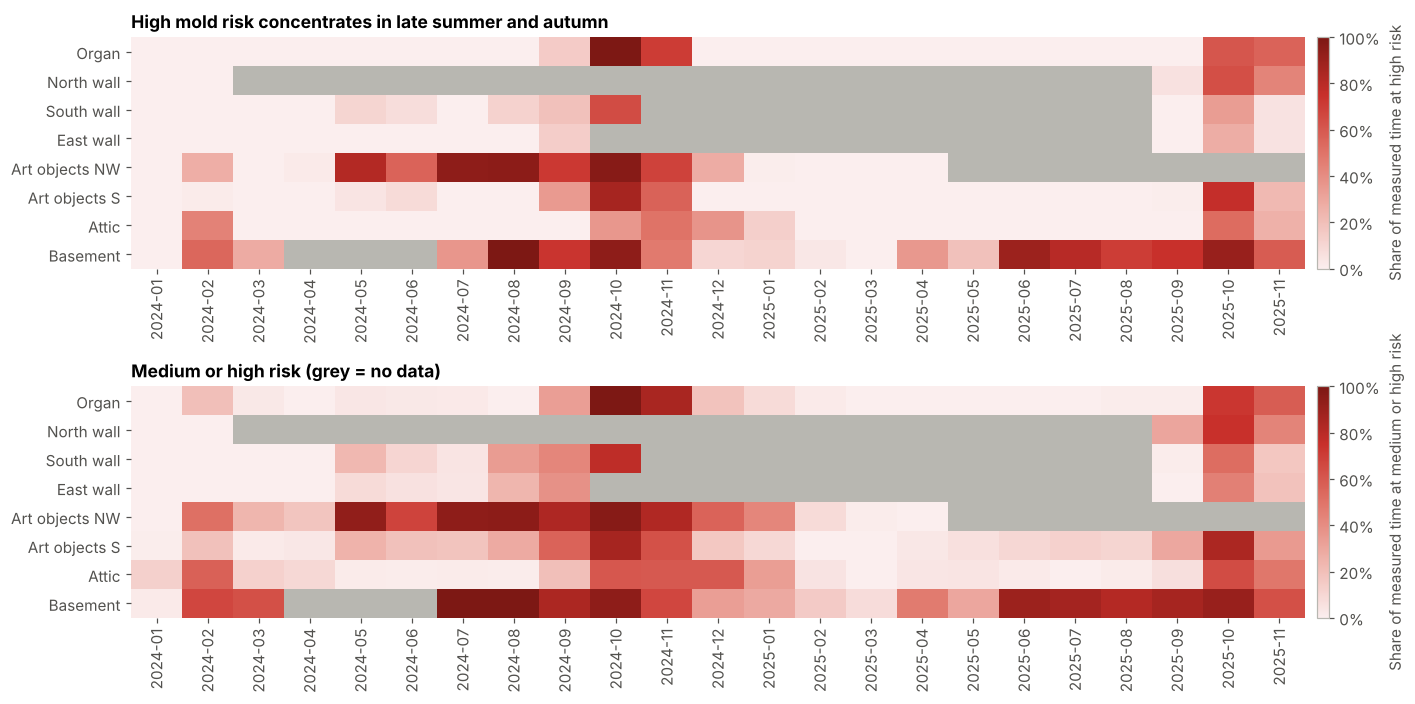

,Organ,North wall,South wall,East wall,Art objects NW,Art objects S,Attic,Basement
Jan,0.00,0.00,0.00,0.00,0.00,0.00,0.09,0.08
Feb,0.00,0.00,0.00,0.00,0.12,0.01,0.23,0.29
Mar,0.00,NaN,0.00,0.00,0.00,0.00,0.00,0.11
Apr,0.00,NaN,0.00,0.00,0.02,0.00,0.00,0.36
May,0.00,NaN,0.11,0.00,0.82,0.02,0.00,0.19
Jun,0.00,NaN,0.07,0.00,0.56,0.04,0.00,0.89
Jul,0.00,NaN,0.00,0.00,0.94,0.00,0.00,0.74
Aug,0.00,NaN,0.12,0.00,0.95,0.00,0.00,0.85
Sep,0.07,0.05,0.10,0.07,0.72,0.18,0.00,0.74
Oct,0.80,0.64,0.48,0.27,0.96,0.81,0.44,0.92


In [3]:
mp_high = R.monthly_profile(risk, 2)
mp_elev = R.monthly_profile(risk, 1, at_least=True)
fig, axes = plt.subplots(2, 1, figsize=(13, 6.5))
P.calendar_heatmap(mp_high, "High mold risk concentrates in late summer and autumn", "Share of measured time at high risk", ax=axes[0])
P.calendar_heatmap(mp_elev, "Medium or high risk (grey = no data)", "Share of measured time at medium or high risk", ax=axes[1])
plt.tight_layout(); P.save(fig, "04_monthly_profile.png"); plt.show()
results.save_table(mp_high.round(3), "risk_monthly_high")
results.save_table(mp_elev.round(3), "risk_monthly_elevated")
season = risk.groupby(risk.index.month).apply(lambda g: (g == 2).sum() / g.notna().sum())
season.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
display(season.rename(columns=names).round(2))

### Episodes of high risk

In [4]:
ep_rows = []
for s in C.INDOOR:
    ep = episodes(risk[s].eq(2).astype(float).where(risk[s].notna()))
    ep["location"] = names[s]
    ep_rows.append(ep)
eps = pd.concat(ep_rows)
longest = eps.sort_values("duration_h", ascending=False).groupby("location").head(1)
longest["duration_days"] = (longest.duration_h / 24).round(1)
display(longest[["location", "start", "end", "duration_days"]])
results.save_table(longest, "risk_longest_episodes")
eps.to_csv(C.TABLE_DIR / "risk_high_episodes.csv", index=False)

,location,start,end,duration_days
7,Organ,2024-10-05 10:40:00+02:00,2024-11-20 01:00:00+01:00,45.7
30,Art objects NW,2024-07-08 02:40:00+02:00,2024-08-21 22:20:00+02:00,44.8
62,Basement,2025-10-04 02:00:00+02:00,2025-11-17 20:00:00+01:00,44.8
5,North wall,2025-10-09 15:40:00+02:00,2025-10-19 04:00:00+02:00,9.5
45,South wall,2024-10-18 08:20:00+02:00,2024-10-27 06:00:00+01:00,9.0
48,Art objects S,2024-10-26 17:00:00+02:00,2024-11-03 11:00:00+01:00,7.8
25,Attic,2024-11-09 01:20:00+01:00,2024-11-16 06:00:00+01:00,7.2
7,East wall,2025-10-14 10:20:00+02:00,2025-10-19 01:00:00+02:00,4.6


## 2 · Fair comparison: identical time windows

The full-period numbers above compare different periods (the north wall was measured
only in Jan–Feb 2024 and Sep–Nov 2025, the north-west art objects never in autumn 2025,
the basement not in spring 2024). A location measured mostly in autumn would look worse
simply because autumn is the risky season. We therefore compare locations **only over
readings where both (or all) have valid data**.

### 2a · Two common windows with almost all locations

In [5]:
win_A = R.common_mask(risk, C.INDOOR) & (risk.index < pd.Timestamp("2024-04-01", tz=C.LOCAL_TZ))
win_B_locs = [s for s in C.INDOOR if s != "K1"]
win_B = R.common_mask(risk, win_B_locs) & (risk.index >= pd.Timestamp("2025-09-01", tz=C.LOCAL_TZ))
print("Window A (winter 2024, all 8 locations):", risk.index[win_A].min(), "->", risk.index[win_A].max(), f"{win_A.sum() / 3:.0f} h")
print("Window B (autumn 2025, 7 locations, no NW art objects):", risk.index[win_B].min(), "->", risk.index[win_B].max(), f"{win_B.sum() / 3:.0f} h")
sA = R.summarize(risk[C.INDOOR], win_A)
sB = R.summarize(risk[win_B_locs], win_B)
cmp = pd.DataFrame({"A: share high": sA.share_high, "A: share medium": sA.share_medium, "A: rank": sA["rank"],
                    "B: share high": sB.share_high, "B: share medium": sB.share_medium, "B: rank": sB["rank"]}).rename(index=names)
display(cmp.round(3))
results.save_table(cmp.round(4), "risk_common_windows")

Window A (winter 2024, all 8 locations): 2024-01-20 10:40:00+01:00 -> 2024-02-16 08:40:00+01:00 646 h
Window B (autumn 2025, 7 locations, no NW art objects): 2025-09-05 12:00:00+02:00 -> 2025-11-29 17:00:00+01:00 1542 h


,A: share high,A: share medium,A: rank,B: share high,B: share medium,B: rank
location,,,,,,
North wall,0.000,0.001,7.0,0.487,0.153,2.0
East wall,0.000,0.001,6.0,0.151,0.148,7.0
South wall,0.000,0.000,8.0,0.181,0.145,6.0
Attic,0.255,0.188,2.0,0.273,0.125,5.0
Art objects NW,0.046,0.207,3.0,NaN,NaN,NaN
Art objects S,0.000,0.061,5.0,0.400,0.176,4.0
Basement,0.281,0.137,1.0,0.871,0.050,1.0
Organ,0.000,0.126,4.0,0.471,0.062,3.0


### 2b · Pairwise comparison on shared readings

For every pair of locations we compute the risk score (share high + 0.5 × share medium)
on exactly the readings where both have data (at least 500 shared hours). A location
"wins" a pair if its score is higher. The final ranking counts wins minus losses
(Copeland ranking) and is the **main ranking** used in the client story, because no
comparison is biased by sensor outages.

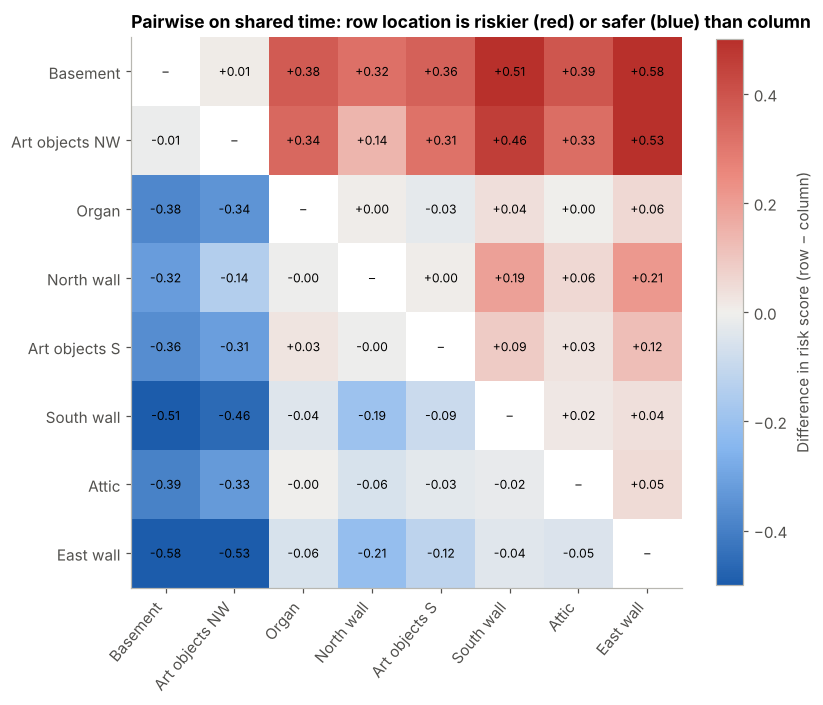

,wins − losses,full-period score,full-period rank,pairwise rank
Basement,7,0.568,1.0,1
Art objects NW,5,0.505,2.0,2
Organ,1,0.159,6.0,3
North wall,1,0.341,3.0,3
Art objects S,1,0.185,4.0,3
South wall,-3,0.164,5.0,6
Attic,-5,0.152,7.0,7
East wall,-7,0.083,8.0,8


In [6]:
def pairwise_ranking(rk: pd.DataFrame, min_hours: float = 500) -> tuple[pd.DataFrame, pd.Series]:
    locs = list(rk.columns)
    diff = pd.DataFrame(np.nan, index=locs, columns=locs)
    for a, b in itertools.permutations(locs, 2):
        m = rk[[a, b]].notna().all(axis=1)
        if m.sum() / 3 < min_hours:
            continue
        sc = R.summarize(rk[[a, b]], m)["score"]
        diff.loc[a, b] = sc[a] - sc[b]
    copeland = (np.sign(diff) > 0).sum(axis=1) - (np.sign(diff) < 0).sum(axis=1)
    return diff, copeland.sort_values(ascending=False)

diff, copeland = pairwise_ranking(risk)
fig, ax = plt.subplots(figsize=(8, 6.5))
order = list(copeland.index)
d = diff.loc[order, order]
im = ax.imshow(d, cmap=P.DIVERGING, vmin=-0.5, vmax=0.5)
for i in range(len(order)):
    for j in range(len(order)):
        v = d.iloc[i, j]
        ax.text(j, i, "–" if np.isnan(v) else f"{v:+.2f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(order)), [names[s] for s in order], rotation=50, ha="right")
ax.set_yticks(range(len(order)), [names[s] for s in order]); ax.grid(False)
ax.set_title("Pairwise on shared time: row location is riskier (red) or safer (blue) than column")
fig.colorbar(im, ax=ax, fraction=0.04, label="Difference in risk score (row − column)")
P.save(fig, "04_pairwise.png"); plt.show()
rank_tab = pd.DataFrame({"wins − losses": copeland, "full-period score": full["score"].reindex(copeland.index).round(3),
                         "full-period rank": full["rank"].reindex(copeland.index)}).rename(index=names)
rank_tab["pairwise rank"] = rank_tab["wins − losses"].rank(ascending=False, method="min").astype(int)
display(rank_tab)
results.save_table(rank_tab, "risk_ranking")
results.update(ranking_pairwise=[names[s] for s in copeland.index],
               ranking_codes=list(copeland.index),
               share_high={names[s]: float(full.loc[s, "share_high"]) for s in C.INDOOR},
               share_elevated={names[s]: float(full.loc[s, "share_high"] + full.loc[s, "share_medium"]) for s in C.INDOOR},
               longest_high_days={r.location: float(r.duration_days) for r in longest.itertuples()},
               winA_hours=float(win_A.sum() / 3), winB_hours=float(win_B.sum() / 3))

## 3 · Validation without ground truth

There are no mold observations, so we validate the *method*: (a) are rankings robust to
the uncertain thresholds, (b) are results physically plausible, (c) do overlapping
periods agree?

### 3a · Sensitivity of the ranking to thresholds and LIM class

36 configurations: LIM class I / II × dew point margin 2 / 3 / 4 °C × persistence share
30 / 50 / 70 % × humidity basis (surface where available / room air everywhere).

,median rank,best rank,worst rank,share of configs in top 3
Basement,1.0,1.0,2.0,1.000000
Art objects NW,2.0,1.0,2.0,1.000000
Art objects S,3.0,3.0,7.0,0.583333
Organ,4.0,3.0,8.0,0.277778
North wall,5.0,3.0,6.0,0.250000
Attic,5.0,4.0,8.0,0.000000
South wall,6.0,5.0,7.0,0.000000
East wall,8.0,6.0,8.0,0.000000


Spearman correlation with the default ranking: min 0.66, median 0.82


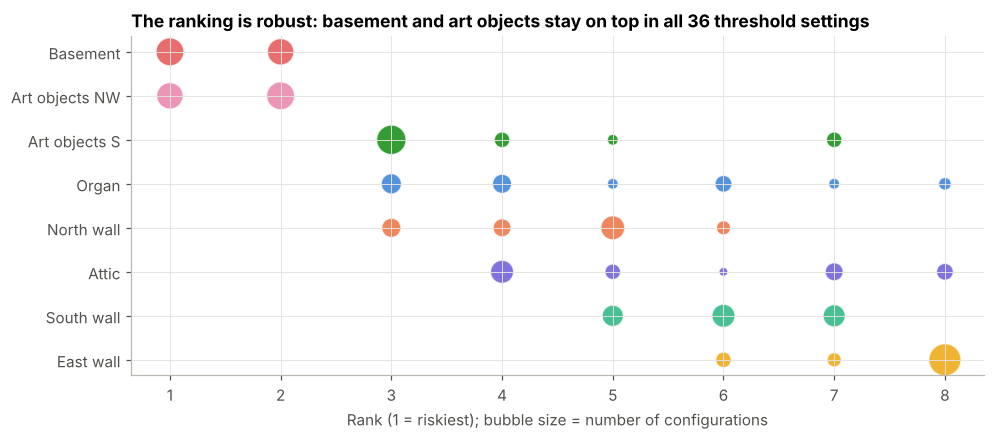

In [7]:
configs, ranks, scores = [], {}, {}
for lim_class, mc, ps, basis in itertools.product(["I", "II"], C.MARGIN_SENSITIVITY, [0.3, 0.5, 0.7], ["auto", "air"]):
    rk = R.risk_table(df, lim_class=lim_class, margin_crit=mc, persist_share=ps, basis=basis)
    _, cop = pairwise_ranking(rk)
    key = f"LIM {lim_class} | margin {mc:g} | persist {ps:.0%} | {basis}"
    ranks[key] = cop.rank(ascending=False, method="min")
    scores[key] = R.summarize(rk)["score"]
ranks = pd.DataFrame(ranks).T[C.INDOOR]
scores = pd.DataFrame(scores).T[C.INDOOR]
default_key = "LIM I | margin 3 | persist 50% | auto"
rho = ranks.apply(lambda r: R.rank_correlation(r, ranks.loc[default_key]), axis=1)
sens = pd.DataFrame({"median rank": ranks.median(), "best rank": ranks.min(), "worst rank": ranks.max(),
                     "share of configs in top 3": (ranks <= 3).mean()}).rename(index=names).sort_values("median rank")
display(sens)
print(f"Spearman correlation with the default ranking: min {rho.min():.2f}, median {rho.median():.2f}")
results.save_table(ranks.rename(columns=names), "sensitivity_ranks")
results.save_table(sens, "sensitivity_summary")
results.update(sens_rho_min=float(rho.min()), sens_rho_median=float(rho.median()), n_configs=len(ranks))

fig, ax = plt.subplots(figsize=(10, 4))
ordr = list(sens.index)
codes = {v: k for k, v in names.items()}
for i, nm in enumerate(ordr):
    r = ranks[codes[nm]]
    vc = r.value_counts()
    ax.scatter(vc.index, [i] * len(vc), s=vc.values * 18, color=P.LOCATION_COLORS[codes[nm]], alpha=0.8, edgecolor="white")
ax.set_yticks(range(len(ordr)), ordr); ax.invert_yaxis()
ax.set_xticks(range(1, 9)); ax.set_xlabel("Rank (1 = riskiest); bubble size = number of configurations")
ax.set_title("The ranking is robust: basement and art objects stay on top in all 36 threshold settings")
P.save(fig, "04_sensitivity.png"); plt.show()

In [8]:
lim_cmp = pd.DataFrame({"share high, LIM I": scores.loc[default_key],
                        "share high, LIM II": scores.loc["LIM II | margin 3 | persist 50% | auto"],
                        "margin 2 °C": scores.loc["LIM I | margin 2 | persist 50% | auto"],
                        "margin 4 °C": scores.loc["LIM I | margin 4 | persist 50% | auto"],
                        "room-air basis": scores.loc["LIM I | margin 3 | persist 50% | air"]}).rename(index=names)
print("Risk score (share high + 0.5 × share medium) under alternative settings:")
display(lim_cmp.round(3))
results.save_table(lim_cmp.round(4), "sensitivity_scores")

Risk score (share high + 0.5 × share medium) under alternative settings:


,"share high, LIM I","share high, LIM II",margin 2 °C,margin 4 °C,room-air basis
location,,,,,
Organ,0.159,0.092,0.155,0.211,0.093
North wall,0.341,0.118,0.341,0.414,0.221
South wall,0.164,0.031,0.164,0.222,0.130
East wall,0.083,0.008,0.083,0.129,0.068
Art objects NW,0.505,0.343,0.491,0.598,0.519
Art objects S,0.185,0.081,0.185,0.185,0.185
Attic,0.152,0.067,0.152,0.152,0.152
Basement,0.568,0.428,0.568,0.568,0.568


### 3b · Physical plausibility

Expectations from building physics: (1) the north-facing wall gets no sun and should be
colder at the surface (relative to the room) and riskier than the south wall; (2) the
basement is coolest relative to outside in summer, so humid summer air should make it
critical then; (3) risk should be highest when the interior is still cool but the
outside air still carries a lot of moisture (late summer and autumn), and low in winter
when outside air is dry.

In [9]:
m_ns = df[["surf_temp_AWn", "surf_temp_AWs", "surf_temp_AWo"]].notna().all(axis=1)
from src.features import location_features
pl = {}
for s in ["AWn", "AWs", "AWo"]:
    f = location_features(df, s)[m_ns]
    pl[names[s]] = {"mean surface temp (°C)": f.surf_temp.mean(), "mean surface − air (°C)": f.surf_minus_air.mean(),
                    "mean dew point margin (°C)": f.margin.mean(), "share above LIM": f.crit_lim.mean(),
                    "share high risk": (risk.loc[m_ns, s] == 2).mean()}
plaus = pd.DataFrame(pl).T.round(3)
print(f"Walls on identical readings ({m_ns.sum() / 3:.0f} h):"); display(plaus)
results.save_table(plaus, "plausibility_walls")
heat = risk.index.month.isin(C.HEATING_MONTHS)
hs = pd.DataFrame({"high share, heating season": (risk[heat] == 2).sum() / risk[heat].notna().sum(),
                   "high share, Jun-Sep": (risk[risk.index.month.isin([6, 7, 8, 9])] == 2).sum() / risk[risk.index.month.isin([6, 7, 8, 9])].notna().sum()}).rename(index=names)
display(hs.round(3))
results.update(plaus_north_margin=float(plaus.loc[names["AWn"], "mean dew point margin (°C)"]),
               plaus_south_margin=float(plaus.loc[names["AWs"], "mean dew point margin (°C)"]),
               plaus_north_high=float(plaus.loc[names["AWn"], "share high risk"]),
               plaus_south_high=float(plaus.loc[names["AWs"], "share high risk"]))

Walls on identical readings (2713 h):


,mean surface temp (°C),mean surface − air (°C),mean dew point margin (°C),share above LIM,share high risk
North wall,12.902,-0.403,4.376,0.385,0.297
South wall,12.860,-0.214,4.664,0.188,0.105
East wall,13.004,-0.226,4.753,0.171,0.087


,"high share, heating season","high share, Jun-Sep"
Organ,0.233,0.018
North wall,0.368,0.052
South wall,0.153,0.078
East wall,0.060,0.027
Art objects NW,0.240,0.794
Art objects S,0.198,0.053
Attic,0.204,0.000
Basement,0.384,0.800


**Validation result:**
* **Robust ranking.** In all 36 configurations the basement and the north-west art
  objects are in the top 2, and the east wall is always in the bottom three (rank 6–8).
  The Spearman correlation with the default ranking is at least 0.66 (median 0.82). The
  middle of the ranking (organ, north wall, south art objects) swaps places depending on the
  thresholds. Absolute shares depend strongly on the thresholds (LIM class II roughly
  halves them), so the client story communicates **relative priorities and periods**, not
  exact percentages.
* **North vs south (identical readings).** The north wall's surface is clearly colder
  *relative to the room air* (−0.40 vs −0.21 °C), its dew point margin is smaller
  (4.4 vs 4.7 °C), it is twice as often above the mold limit (39 % vs 19 %) and about three
  times as often at high risk (30 % vs 11 %) – the physically expected order. The absolute
  surface temperatures are almost equal, which is a reminder that these sensors cover
  mostly autumn and late winter.
* **Seasonality.** The basement and the north-west art objects (cold corner) are
  critical in **summer** (≈ 80 % high-risk share June–September), when warm humid air meets
  cold surfaces; the nave (organ, walls, south art objects) in **October–November**, when the
  outside air is still humid but the building has cooled down. From December to April risk
  is low almost everywhere. This matches the expectation and supports the index.
* **Common windows.** In winter 2024 (window A, about 650 h) only the basement, attic and
  north-west art objects show elevated risk; in autumn 2025 (window B, about 1,540 h) the north wall
  is second after the basement, clearly ahead of the south and east walls.

## 4 · Early-warning model (optional): "high risk in the next 24 hours?"

Not trained to reproduce the rule from the same inputs (that would be circular). Target:
*any* high-risk reading in the next 24 h. Inputs: current outside conditions and their
24 h mean/change, current indoor state, time features. Shallow decision tree (depth 3,
balanced class weights), **time split** (train before the split date, last 24 h before the
split purged), compared with two naive baselines: **persistence** ("high now → high next
24 h") and **rule of thumb** ("humidity above LIM now"). Locations with complete records:
organ, south art objects, basement. Data is sampled hourly.

In [10]:
rows, fits = [], {}
for loc in ["O1", "K2", "Ke1"]:
    data = M.build_dataset(df, risk[loc], loc)
    for split in ["2025-03-01", "2025-05-01", "2025-07-01"]:
        for fs_name, fs in [("all inputs", M.FEATURES), ("no rule ingredients", M.OUTSIDE_ONLY)]:
            r = M.fit_and_evaluate(data, split, features=fs)
            fits[(loc, split, fs_name)] = r
            for subset in ["all", "onset"]:
                for who, key in [("model", f"model_{subset}"), ("persistence", f"baseline_{subset}"), ("above LIM now", f"above_{subset}")]:
                    if fs_name != "all inputs" and who != "model":
                        continue
                    rows.append(dict(location=names[loc], split=split, features=fs_name if who == "model" else "-",
                                     predictor=who, subset=subset, **{k: r[key][k] for k in ["precision", "recall", "f1", "positives", "n"]}))
ev = pd.DataFrame(rows)
main = ev[(ev.split == "2025-05-01")].pivot_table(index=["location", "subset"], columns=["predictor", "features"], values="f1").round(2)
print("F1 score, split 1 May 2025 (test = May-Nov 2025). 'onset' = hours that are not high-risk now:")
display(main)
results.save_table(ev.round(3), "model_evaluation")
ms = ev[ev.split == "2025-05-01"].copy()
ms["predictor"] = np.where(ms.predictor == "model", "tree (" + ms.features + ")", ms.predictor)
ms = ms.pivot_table(index=["location", "subset"], columns="predictor", values="f1").round(2).reset_index()
ms["subset"] = ms["subset"].map({"all": "all test hours", "onset": "onset hours"})
results.save_table(ms.set_index("location"), "model_f1")

F1 score, split 1 May 2025 (test = May-Nov 2025). 'onset' = hours that are not high-risk now:


predictor            above LIM now      model                     persistence
features                         - all inputs no rule ingredients           -
location      subset                                                         
Art objects S all             0.70       0.91                0.67        0.86
              onset           0.17       0.70                0.33        0.00
Basement      all             0.95       0.92                0.94        0.97
              onset           0.31       0.40                0.28        0.00
Organ         all             0.92       0.96                0.70        0.95
              onset           0.24       0.73                0.18        0.00

In [11]:
split_sens = ev[(ev.features.isin(["all inputs", "-"])) & (ev.subset == "all")].pivot_table(
    index=["location", "split"], columns="predictor", values="f1").round(2)
print("F1 on all test hours for three split dates:"); display(split_sens)
onset_sens = ev[(ev.subset == "onset") & (ev.predictor != "persistence")].pivot_table(
    index=["location", "split"], columns=["predictor", "features"], values=["precision", "recall"]).round(2)
print("Onset hours: precision / recall for three split dates:"); display(onset_sens)

F1 on all test hours for three split dates:


predictor                 above LIM now  model  persistence
location      split                                        
Art objects S 2025-03-01           0.69   0.91         0.86
              2025-05-01           0.70   0.91         0.86
              2025-07-01           0.73   0.91         0.86
Basement      2025-03-01           0.93   0.96         0.96
              2025-05-01           0.95   0.92         0.97
              2025-07-01           0.96   0.94         0.98
Organ         2025-03-01           0.92   0.96         0.95
              2025-05-01           0.92   0.96         0.95
              2025-07-01           0.92   0.96         0.95

Onset hours: precision / recall for three split dates:


precision                                       recall                               
predictor                above LIM now      model                     above LIM now      model                    
features                             - all inputs no rule ingredients             - all inputs no rule ingredients
location      split                                                                                               
Art objects S 2025-03-01          0.12       0.57                0.20          0.32       0.85                1.00
              2025-05-01          0.12       0.58                0.20          0.32       0.89                1.00
              2025-07-01          0.15       0.58                0.20          0.32       0.89                1.00
Basement      2025-03-01          0.23       0.00                0.23          0.35       0.00                0.59
              2025-05-01          0.26       0.25                0.23          0.38       1.00                0.38
              2025-07-01          0.25       0.22                0.25          0.44       0.81                0.44
Organ         2025-03-01          0.21       0.71                0.10          0.27       0.40                1.00
              2025-05-01          0.21       0.57                0.10          0.27       1.00                1.00
              2025-07-01          0.21       0.57                0.10          0.27       1.00                1.00

### Model details for the basement (split 1 May 2025)

train: (Timestamp('2024-01-23 02:00:00+0100', tz='Europe/Berlin'), Timestamp('2025-04-29 23:00:00+0200', tz='Europe/Berlin'), 7943, 0.47991942590960596) 
test: (Timestamp('2025-05-01 00:00:00+0200', tz='Europe/Berlin'), Timestamp('2025-11-29 05:00:00+0100', tz='Europe/Berlin'), 4999, 0.7283456691338268)
|--- high_now <= 0.50
|   |--- crit_share_7d <= 0.36
|   |   |--- lim_excess <= -27.21
|   |   |   |--- class: 0
|   |   |--- lim_excess >  -27.21
|   |   |   |--- class: 0
|   |--- crit_share_7d >  0.36
|   |   |--- in_temp <= 9.00
|   |   |   |--- class: 0
|   |   |--- in_temp >  9.00
|   |   |   |--- class: 1
|--- high_now >  0.50
|   |--- lim_excess <= 0.20
|   |   |--- class: 1
|   |--- lim_excess >  0.20
|   |   |--- out_temp <= 5.36
|   |   |   |--- class: 1
|   |   |--- out_temp >  5.36
|   |   |   |--- class: 1



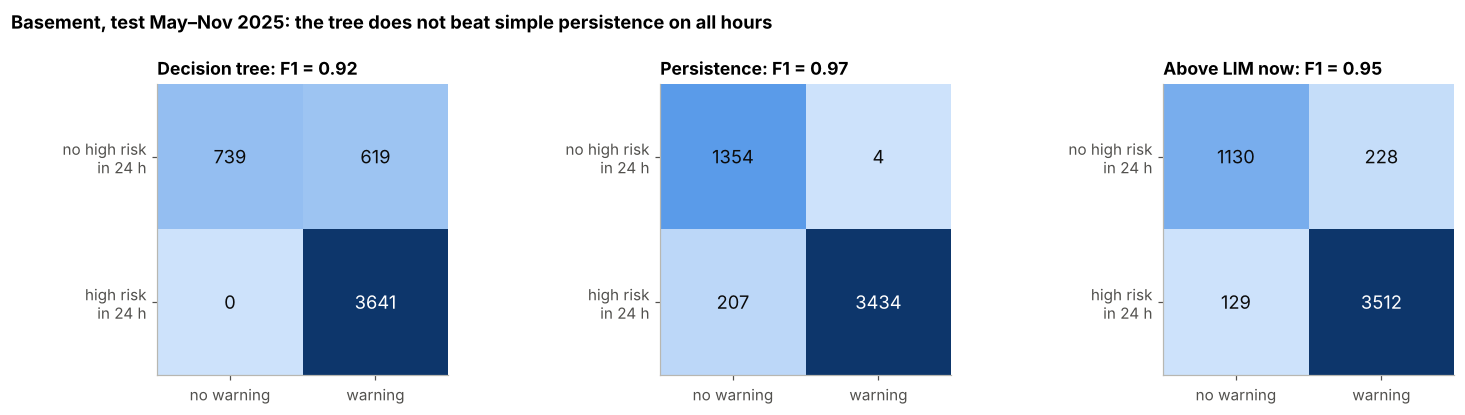

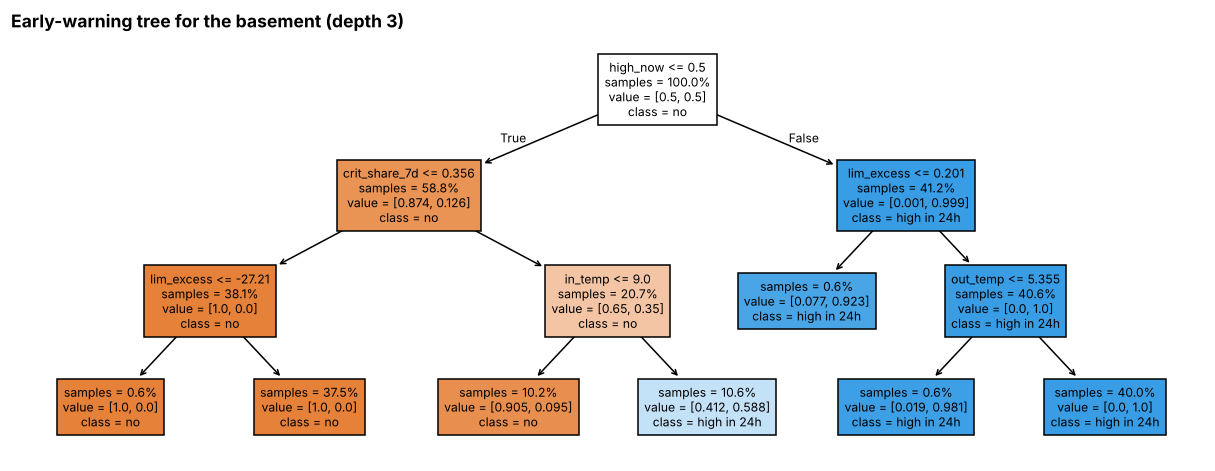

,high_now,crit_share_7d,in_temp,lim_excess,out_temp,out_abs_hum,out_abs_hum_mean_24h,out_temp_change_24h,out_temp_mean_24h,in_rh,crit_share_24h,d_abs_hum_in_out,month,heating_season
importance,0.867,0.075,0.058,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [12]:
r = fits[("Ke1", "2025-05-01", "all inputs")]
print("train:", r["train_period"], "\ntest:", r["test_period"])
print(r["tree_text"])
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (lab, key) in zip(axes, [("Decision tree", "model_all"), ("Persistence", "baseline_all"), ("Above LIM now", "above_all")]):
    m = r[key]
    cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    ax.imshow(cm, cmap=P.SEQ_BLUE); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=12, color="white" if cm[i, j] > cm.max() / 2 else P.INK)
    ax.set_xticks([0, 1], ["no warning", "warning"]); ax.set_yticks([0, 1], ["no high risk\nin 24 h", "high risk\nin 24 h"])
    ax.set_title(f"{lab}: F1 = {m['f1']:.2f}")
plt.suptitle("Basement, test May–Nov 2025: the tree does not beat simple persistence on all hours", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); P.save(fig, "04_confusion_basement.png"); plt.show()

fig, ax = plt.subplots(figsize=(14, 5))
plot_tree(r["model"], feature_names=M.FEATURES, class_names=["no", "high in 24h"], filled=True, ax=ax, fontsize=8, impurity=False, proportion=True)
ax.set_title("Early-warning tree for the basement (depth 3)")
P.save(fig, "04_tree_basement.png"); plt.show()
display(r["importances"].round(3).to_frame("importance").T)

## 5 · Error analysis

Where do the rule and the model fail?

In [13]:
# (a) model errors by month and in fast weather changes (organ, split 1 May 2025)
err_rows = []
for loc in ["O1", "K2", "Ke1"]:
    r = fits[(loc, "2025-05-01", "all inputs")]
    p = r["predictions"].join(M.build_dataset(df, risk[loc], loc)[["out_temp_change_24h"]])
    p["error"] = p["y"] != p["model"]
    p["fast"] = p["out_temp_change_24h"].abs() > 5
    for (mo, g) in p.groupby(p.index.month):
        err_rows.append(dict(location=names[loc], month=mo, error_rate=g.error.mean(), fn=int(((g.y == 1) & (g.model == 0)).sum()),
                             fp=int(((g.y == 0) & (g.model == 1)).sum())))
    print(f"{names[loc]}: error rate with outside temp change > 5 °C/24 h: {p[p.fast].error.mean():.2f} "
          f"(n={p.fast.sum()}) vs otherwise {p[~p.fast].error.mean():.2f}")
err = pd.DataFrame(err_rows).pivot_table(index="month", columns="location", values=["error_rate", "fn", "fp"]).round(2)
display(err)

Organ: error rate with outside temp change > 5 °C/24 h: 0.02 (n=264) vs otherwise 0.01
Art objects S: error rate with outside temp change > 5 °C/24 h: 0.00 (n=264) vs otherwise 0.04
Basement: error rate with outside temp change > 5 °C/24 h: 0.11 (n=264) vs otherwise 0.12


error_rate                           fn                           fp               
location Art objects S Basement Organ Art objects S Basement Organ Art objects S Basement Organ
month                                                                                          
5                 0.00     0.15   0.0           0.0      0.0   0.0           0.0    108.0   0.0
6                 0.00     0.03   0.0           0.0      0.0   0.0           0.0     23.0   0.0
7                 0.01     0.13   0.0           0.0      0.0   0.0           8.0     98.0   0.0
8                 0.00     0.15   0.0           0.0      0.0   0.0           0.0    104.0   0.0
9                 0.06     0.24   0.0          14.0      0.0   0.0          25.0    159.0   0.0
10                0.01     0.06   0.0          11.0      0.0   0.0           0.0     45.0   2.0
11                0.18     0.12   0.1           0.0      0.0   0.0         121.0     82.0  66.0

In [14]:
# (b) the rule after data gaps: the 7-day persistence needs >= 50 % valid data in the window,
#     so for up to 3.5 days after an outage "high" can only come from condensation.
from src.features import location_features, rolling_exposure
rows = []
for s in C.INDOOR:
    f = location_features(df, s)
    share = rolling_exposure(f["crit_lim"], C.PERSIST_WINDOW)["share"]
    blind = f["crit_lim"].eq(1) & share.isna()
    rows.append({"location": names[s], "readings above LIM with too little history": int(blind.sum()),
                 "as share of readings above LIM": blind.sum() / max(f["crit_lim"].eq(1).sum(), 1)})
blind = pd.DataFrame(rows).set_index("location").round(3)
display(blind)
results.save_table(blind, "rule_blind_after_gaps")

,readings above LIM with too little history,as share of readings above LIM
location,,
Organ,0,0.000
North wall,32,0.010
South wall,0,0.000
East wall,0,0.000
Art objects NW,0,0.000
Art objects S,0,0.000
Attic,35,0.004
Basement,251,0.010


**Error analysis and limitations**

* **Model vs baseline (honest result).** Risk is extremely persistent: once high it stays
  high for days. On *all* test hours persistence is hard to beat: the tree is on par at
  the organ (F1 0.96 vs 0.95), better at the south art objects (0.91 vs 0.86) and **worse at
  the basement** (0.92 vs 0.97). Its added value is on **onset hours** (not yet high), where
  persistence never warns: the tree catches most onsets (recall 0.9–1.0) but with many false
  alarms (precision 0.25–0.58). For the basement and the 1 March split it does not warn at
  all, i.e. results are not stable. Without the rule ingredients (weather plus indoor
  temperature/humidity only) onset F1 falls to 0.2–0.3: **weather alone is a weak
  predictor** at a 24 h horizon. Recommendation: use the transparent rule as the operational
  alert; the model is at most an add-on.
* **Season.** All high-risk test hours at the organ and south art objects lie in Sep–Nov
  2025, so the test describes the autumn transition only. Different split dates give
  similar numbers because the positives do not change.
* **Where the model errs.** Errors concentrate in the **transition months** (September and
  November: the tree predicts continuation when the high period has just ended) and in
  frequent false alarms at the basement throughout summer. Contrary to our expectation,
  errors are *not* higher after fast outside temperature changes (> 5 °C in 24 h); the slow
  building smooths them.
* **After gaps.** The persistence part of the rule needs 3.5 days of valid history; just
  after an outage high risk can be under-reported. This affects ≤ 1 % of readings above the
  limit (table above). Missing data is shown as *unknown*, never as low.
* **No ground truth.** No mold inspections exist; the index is a conservative screening
  tool (as intended by the guideline), not a prediction of visible mold.
* **LIM values read visually** (±1 % relative humidity); sensitivity shows that absolute
  shares, not the top/bottom of the ranking, depend on this.
* **Coverage.** The north wall covers only 17 % of the period, the south and east walls about
  half, and **no wall sensor covers winter 2024/25**; the north-west art objects have no
  humidity after April 2025, so they are missing in the risky autumn 2025.
* **Point sensors.** One sensor per wall may not represent corners, areas behind
  furniture or art objects, which are typically colder. Attic, basement and south art objects
  have no surface sensor, so their risk is based on room air (probably underestimated).
* **Outside humidity sensor saturates** (10,541 readings above 100 %) → outside absolute
  humidity is uncertain in fog and rain, which affects the ventilation features.